# 03 · Explore the second datasets: weather and buildings
| Dataset | File | Why we need it |
|---|---|---|
| **Daily weather**, Central Park (Open-Meteo archive, 2023–2025) | `data/raw/weather_daily.csv` | The "stress test" applied equally to every neighborhood |
| **PLUTO** tax lots | `data/raw/pluto.parquet` | Building age and number of apartments, to normalize and explain complaints |

Downloaded with `python -m src.download --only weather` and `--only pluto`.

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from src import config, preprocess as P
from src.plots import save, ACCENT, MUTED

pd.set_option("display.float_format", "{:,.2f}".format)

## Part A: Weather

In [2]:
w = pd.read_csv(config.RAW_WEATHER_FILE, parse_dates=["time"])
print(w.shape); display(w.head())
w.describe().T

(1096, 8)


,time,temperature_2m_max,temperature_2m_min,temperature_2m_mean,precipitation_sum,rain_sum,snowfall_sum,wind_speed_10m_max
0,2023-01-01,52.80,40.50,47.90,0.04,0.04,0.00,10.70
1,2023-01-02,54.70,40.50,46.60,0.04,0.04,0.00,5.50
2,2023-01-03,55.60,44.80,49.60,0.46,0.46,0.00,12.00
3,2023-01-04,64.00,51.00,56.00,0.08,0.08,0.00,10.80
4,2023-01-05,55.60,43.60,49.20,0.00,0.00,0.00,7.90


,count,mean,min,25%,50%,75%,max,std
time,1096,2024-07-01 12:00:00,2023-01-01 00:00:00,2023-10-01 18:00:00,2024-07-01 12:00:00,2025-04-01 06:00:00,2025-12-31 00:00:00,NaN
temperature_2m_max,"1,096.00",63.49,17.20,48.80,63.85,79.30,102.80,17.89
temperature_2m_min,"1,096.00",46.89,1.40,33.88,46.90,60.62,83.20,16.13
temperature_2m_mean,"1,096.00",54.98,11.00,41.40,55.55,69.30,93.40,16.59
precipitation_sum,"1,096.00",0.14,0.00,0.00,0.00,0.10,3.69,0.34
rain_sum,"1,096.00",0.14,0.00,0.00,0.00,0.08,3.69,0.34
snowfall_sum,"1,096.00",0.04,0.00,0.00,0.00,0.00,7.14,0.31
wind_speed_10m_max,"1,096.00",11.57,3.10,8.80,11.00,13.80,34.20,3.92


In [3]:
# Completeness and sanity checks
full_range = pd.date_range(w.time.min(), w.time.max(), freq="D")
print("Missing days:", len(full_range.difference(w.time)))
print("Missing values per column:", w.isna().sum().to_dict())
print("Days with tmin > tmax:", (w.temperature_2m_min > w.temperature_2m_max).sum())

Missing days: 0
Missing values per column: {'time': 0, 'temperature_2m_max': 0, 'temperature_2m_min': 0, 'temperature_2m_mean': 0, 'precipitation_sum': 0, 'rain_sum': 0, 'snowfall_sum': 0, 'wind_speed_10m_max': 0}
Days with tmin > tmax: 0


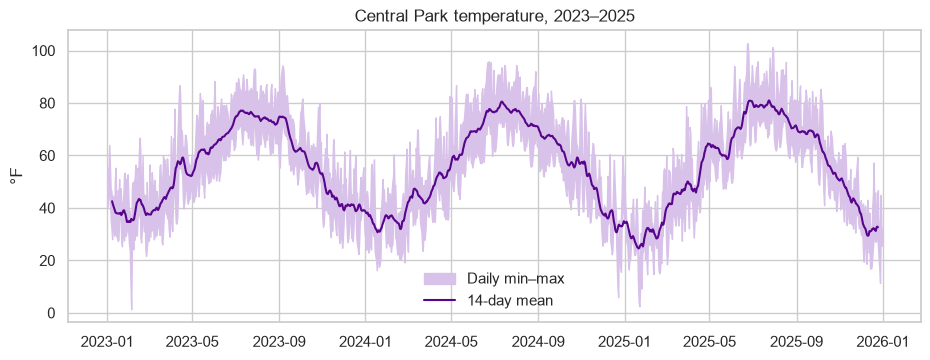

In [4]:
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.fill_between(w.time, w.temperature_2m_min, w.temperature_2m_max, color="#d9c2ea", label="Daily min–max")
ax.plot(w.time, w.temperature_2m_mean.rolling(14, center=True).mean(), color=ACCENT, label="14-day mean")
ax.set(ylabel="°F", title="Central Park temperature, 2023–2025"); ax.legend(frameon=False)
save(fig, "03a_temperature_series")

Heaviest rain days:


,time,precipitation_sum
271,2023-09-29,3.69
351,2023-12-18,3.09
447,2024-03-23,2.58
279,2023-10-07,2.17
118,2023-04-29,2.02


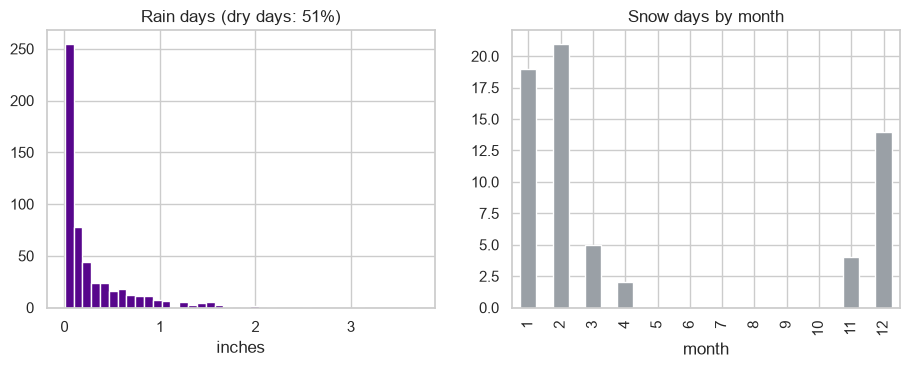

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].hist(w.precipitation_sum[w.precipitation_sum > 0], bins=40, color=ACCENT)
axes[0].set(title=f"Rain days (dry days: {(w.precipitation_sum == 0).mean():.0%})", xlabel="inches")
w.assign(month=w.time.dt.month).query("snowfall_sum > 0").groupby("month").size().reindex(range(1, 13), fill_value=0) \
    .plot(kind="bar", ax=axes[1], color=MUTED, title="Snow days by month", xlabel="month")
save(fig, "03b_rain_snow")
print("Heaviest rain days:"); w.nlargest(5, "precipitation_sum")[["time", "precipitation_sum"]]

**Notes:**
- The series is complete, with no gaps and no impossible values.
- Open-Meteo values are **model reanalysis** (ERA5) for the Central Park grid cell, not a weather-station reading. NOAA's Central Park station (`USW00094728`) is the official alternative.
- One point represents the whole city. That's reasonable for temperature, but rain can be very local.

## Part B: PLUTO (buildings)

In [6]:
p = pd.read_parquet(config.RAW_PLUTO_FILE)
print(p.shape); display(p.head())
p.isna().mean().mul(100).round(1).rename("% missing").to_frame().T

(858312, 12)


,bbl,borough,zipcode,cd,yearbuilt,unitsres,unitstotal,numfloors,bldgclass,landuse,latitude,longitude
0,1000010010.00000000,MN,10004,101,1900,0,1,3.5000000,Y4,8,40.6887632,-74.0187179
1,1000010100.00000000,MN,NaN,101,0,0,1,NaN,Y4,8,40.6927301,-74.0138617
2,1000010101.00000000,MN,10004,101,1900,0,0,NaN,P7,8,40.6899196,-74.0453371
3,1000010111.00000000,MN,10004,101,0,0,1,3.0000000,Y4,8,40.6929217,-74.0176373
4,1000010112.00000000,MN,10004,101,0,0,1,NaN,Y4,8,40.6929271,-74.0183477


,bbl,borough,zipcode,cd,yearbuilt,unitsres,unitstotal,numfloors,bldgclass,landuse,latitude,longitude
% missing,0.00,0.00,0.20,0.10,0.00,0.00,0.00,4.90,0.00,0.30,0.10,0.10


In [7]:
# Format problems to fix in cleaning
print("BBL as delivered:", p.bbl.head(3).tolist(), "→ needs normalizing to 10 digits to match 311")
num = p[["yearbuilt", "unitsres", "unitstotal", "numfloors"]].apply(pd.to_numeric, errors="coerce")
print("Lots with yearbuilt = 0 (unknown):", (num.yearbuilt == 0).sum())
num.describe().T

BBL as delivered: ['1000010010.00000000', '1000010100.00000000', '1000010101.00000000'] → needs normalizing to 10 digits to match 311


Lots with yearbuilt = 0 (unknown): 39842


,count,mean,std,min,25%,50%,75%,max
yearbuilt,"858,002.00","1,851.47",409.76,0.00,"1,920.00","1,930.00","1,960.00","2,026.00"
unitsres,"857,904.00",4.36,34.25,0.00,1.00,2.00,2.00,"10,914.00"
unitstotal,"857,905.00",4.83,47.54,0.00,1.00,2.00,2.00,"23,251.00"
numfloors,"816,103.00",2.49,2.05,0.00,2.00,2.00,2.75,342.87


Residential lots: 767,749 of 858,312 (89%); total apartments: 3,741,982


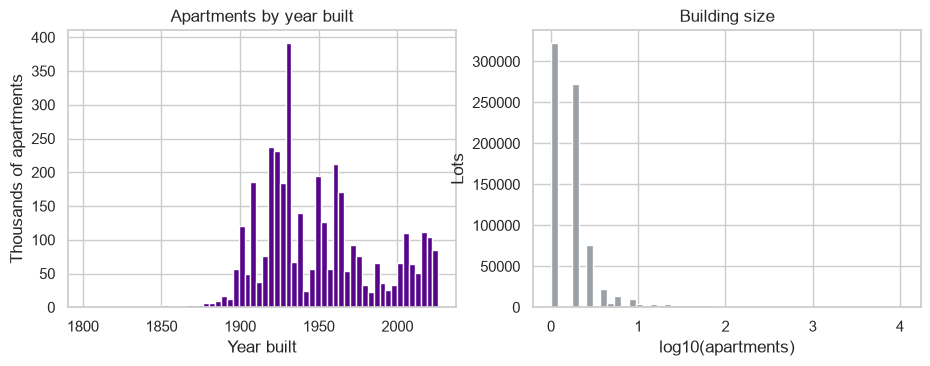

In [8]:
res = num[num.unitsres > 0]
print(f"Residential lots: {len(res):,} of {len(p):,} ({len(res) / len(p):.0%}); total apartments: {res.unitsres.sum():,.0f}")
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].hist(res.yearbuilt[res.yearbuilt > 1800], bins=60, weights=res.unitsres[res.yearbuilt > 1800] / 1000, color=ACCENT)
axes[0].set(title="Apartments by year built", xlabel="Year built", ylabel="Thousands of apartments")
axes[1].hist(np.log10(res.unitsres), bins=50, color=MUTED)
axes[1].set(title="Building size", xlabel="log10(apartments)", ylabel="Lots")
save(fig, "03c_pluto_age_size")

## Part C: Do the datasets link to 311?

In [9]:
c = pd.read_parquet(config.CLEAN_311_FILE, columns=["bbl", "complaint_type", "date"])
pluto_bbl = set(P.normalize_bbl(p.bbl).dropna())
match = c.assign(has_bbl=c.bbl.notna(), in_pluto=c.bbl.isin(pluto_bbl))
match.groupby("complaint_type", observed=True)[["has_bbl", "in_pluto"]].mean().mul(100).round(1) \
    .rename(columns={"has_bbl": "% with BBL", "in_pluto": "% matching PLUTO"})

,% with BBL,% matching PLUTO
complaint_type,,
Dirty Condition,88.60,88.10
HEAT/HOT WATER,99.60,99.20
Noise - Residential,97.00,96.80
Noise - Street/Sidewalk,86.50,86.20
Rodent,96.90,96.30
Sewer,81.20,80.90
Snow or Ice,86.00,85.40
Water System,79.40,79.00


Spearman ρ: -0.89


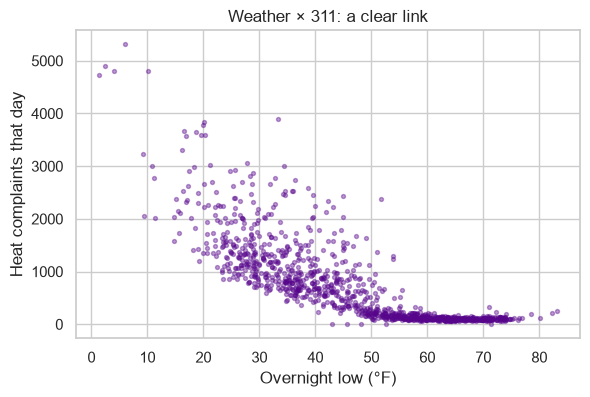

In [10]:
# First look at the link to weather: daily heat complaints vs overnight low
heat = c[c.complaint_type == "HEAT/HOT WATER"].groupby("date").size().rename("heat")
daily = w.set_index("time")[["temperature_2m_min"]].join(heat).fillna(0)
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.scatter(daily.temperature_2m_min, daily.heat, s=8, alpha=0.4, color=ACCENT)
ax.set(xlabel="Overnight low (°F)", ylabel="Heat complaints that day", title="Weather × 311: a clear link")
print("Spearman ρ:", round(daily.temperature_2m_min.rank().corr(daily.heat.rank()), 2))

→ Next: **04_clean_weather_pluto.ipynb**